# Week 3: Prescriptive Dynamic Pricing Optimization Engine
## Constrained Resource Allocation via SciPy & Causal Machine Learning

Welcome to the **Week 3 Prescriptive Optimization Engine** of the **EconoCausal** system.
In Weeks 1 and 2, we built the Causal DAG and trained an EconML Double Machine Learning (`LinearDML` + `LightGBM`) model to estimate the Individual Treatment Effect (ITE) $\tau_i(t)$ of discounts ($10 and $20) for each customer.

In Week 3, we transition from **Predictive / Causal Inference** to **Prescriptive Decision-Making**:
How do we strategically allocate a finite marketing budget (e.g., $5,000) across thousands of customers and multiple discount tiers to maximize incremental conversions?

---
### Mathematical Formulation: Multiple-Choice Knapsack Problem (MCKP)

Let:
- $N$ = total number of customers
- $x_{i, 10} \in \{0, 1\}$ = binary decision to assign a $\$10$ discount to customer $i$
- $x_{i, 20} \in \{0, 1\}$ = binary decision to assign a $\$20$ discount to customer $i$
- $\tau_{i, 10}$ = estimated ITE of $\$10$ discount (lift in conversion probability)
- $\tau_{i, 20}$ = estimated ITE of $\$20$ discount (lift in conversion probability)
- $c_{10}, c_{20}$ = cost per discount ($10 and $20, respectively)
- $B$ = total marketing budget constraint

$$\max_{\{x_{i, 10}, x_{i, 20}\}} \sum_{i=1}^N \left( \tau_{i, 10} x_{i, 10} + \tau_{i, 20} x_{i, 20} \right)$$

$$\text{subject to:}$$
1. **Budget Constraint:**
$$\sum_{i=1}^N \left( c_{10} x_{i, 10} + c_{20} x_{i, 20} \right) \le B$$

2. **Exclusivity Constraint (At most one promotion per customer):**
$$x_{i, 10} + x_{i, 20} \le 1, \quad \forall i \in \{1, \dots, N\}$$

3. **Integrality Constraint:**
$$x_{i, 10}, x_{i, 20} \in \{0, 1\}, \quad \forall i \in \{1, \dots, N\}$$


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import csc_matrix, eye, hstack, vstack

# Set aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)
print("Libraries loaded successfully!")


Libraries loaded successfully!


### 1. Load Individual Treatment Effect (ITE) Predictions
We load the customer-level ITE predictions generated by EconML Double ML in Week 2 (`data/ite_predictions.csv`).
Each record contains the predicted incremental conversion lift $\tau_{i, 10}$ and $\tau_{i, 20}$.


In [2]:
df_ite = pd.read_csv('data/ite_predictions.csv')
print(f"Loaded {len(df_ite):,} customer records.")
df_ite[['client_id', 'age', 'has_redeemed', 'ite_10', 'ite_20']].head()


Loaded 10,000 customer records.


,client_id,age,has_redeemed,ite_10,ite_20
0,582caf677d,43,0,-0.007027,0.068457
1,7345cbbfdb,72,1,0.043879,0.045112
2,ba7e16dc51,43,1,0.016555,0.048884
3,f47784cc95,38,1,0.031525,0.047295
4,02a400777e,53,1,0.030411,0.047079


### 2. Inspecting Price Elasticity and Marginal ROI
Let us compute the marginal ROI for each customer across both promotion upgrade steps:
- **Phase 1 ROI ($0 $\to$ $10):** $\text{ROI}_1 = \frac{\tau_{i, 10}}{c_{10}}$
- **Phase 2 ROI ($10 $\to$ $20):** $\text{ROI}_2 = \frac{\tau_{i, 20} - \tau_{i, 10}}{c_{20} - c_{10}}$


In [3]:
df_ite['marginal_roi_10'] = df_ite['ite_10'] / 10.0
df_ite['marginal_roi_upgrade'] = (df_ite['ite_20'] - df_ite['ite_10']) / 10.0

print("Summary Statistics of Marginal ROI:")
df_ite[['marginal_roi_10', 'marginal_roi_upgrade']].describe().T


Summary Statistics of Marginal ROI:


,count,mean,std,min,25%,50%,75%,max
marginal_roi_10,10000.0,0.002328,0.001449,-0.002904,0.001658,0.002707,0.003345,0.005221
marginal_roi_upgrade,10000.0,0.002625,0.001967,-0.000845,0.001330,0.002070,0.003227,0.008596


### 3. Exact Binary Mixed-Integer Linear Programming (SciPy HiGHS Solver)
We construct the sparse constraint matrix $A$ and solve the binary integer program using the state-of-the-art HiGHS solver in SciPy (`scipy.optimize.milp`).


In [4]:
def solve_milp(df, budget=5000.0, cost_10=10.0, cost_20=20.0):
    n = len(df)
    tau_10 = df['ite_10'].values
    tau_20 = df['ite_20'].values
    
    # SciPy minimizes, so we negate coefficients
    c = - np.concatenate([tau_10, tau_20])
    
    # Budget constraint: 1 row
    row_budget = np.concatenate([np.full(n, cost_10), np.full(n, cost_20)])
    A_budget = csc_matrix(row_budget.reshape(1, 2 * n))
    
    # Exclusivity constraint: n rows
    A_excl = hstack([eye(n, format='csc'), eye(n, format='csc')])
    A = vstack([A_budget, A_excl])
    
    lhs = np.zeros(1 + n)
    rhs = np.concatenate([[budget], np.ones(n)])
    constraints = LinearConstraint(A, lhs, rhs)
    integrality = np.ones(2 * n) # All binary
    bounds = Bounds(0, 1)
    
    res = milp(c=c, constraints=constraints, integrality=integrality, bounds=bounds)
    
    if not res.success:
        raise RuntimeError("MILP failed or timed out.")
        
    x_10 = res.x[:n].round().astype(int)
    x_20 = res.x[n:].round().astype(int)
    
    res_df = df.copy()
    rec = np.zeros(n, dtype=int)
    rec[x_10 == 1] = 10
    rec[x_20 == 1] = 20
    res_df['recommended_discount'] = rec
    
    lift = np.zeros(n)
    lift[x_10 == 1] = tau_10[x_10 == 1]
    lift[x_20 == 1] = tau_20[x_20 == 1]
    res_df['expected_lift'] = lift
    
    cost = np.zeros(n)
    cost[x_10 == 1] = cost_10
    cost[x_20 == 1] = cost_20
    res_df['treatment_cost'] = cost
    
    return res_df

# Benchmark on 1,000 customers to demonstrate HiGHS branch-and-cut optimization
t0 = time.time()
milp_sample = solve_milp(df_ite.head(1000), budget=1000.0)
milp_time = time.time() - t0
print(f"HiGHS MILP solved 1,000 customers in {milp_time:.3f} seconds.")
print(f"Total budget spent: ${milp_sample['treatment_cost'].sum():,.2f}")
print(f"Incremental buyers gained: {milp_sample['expected_lift'].sum():.2f}")


HiGHS MILP solved 1,000 customers in 0.121 seconds.


Total budget spent: $1,000.00
Incremental buyers gained: 4.13


### 4. Ultra-Fast Marginal-ROI Greedy Solver ($O(N \log N)$)
For real-time interactive dashboards (such as Streamlit sliders), we need sub-10ms response times across 10,000+ customers.
Because the linear relaxation of the Multiple-Choice Knapsack Problem has the greedy choice property, ranking actions by marginal conversion lift per dollar spent achieves near-identical objective value in milliseconds.


In [5]:
def solve_greedy(df, budget=5000.0, cost_10=10.0, cost_20=20.0):
    n = len(df)
    tau_10 = df['ite_10'].values
    tau_20 = df['ite_20'].values
    
    roi_1 = tau_10 / cost_10
    cost_diff = max(1.0, cost_20 - cost_10)
    roi_2 = (tau_20 - tau_10) / cost_diff
    
    actions = []
    for i in range(n):
        if roi_1[i] > 0:
            actions.append(('10', i, cost_10, tau_10[i], roi_1[i]))
        if roi_2[i] > 0:
            actions.append(('upgrade_20', i, cost_diff, tau_20[i] - tau_10[i], roi_2[i]))
            
    actions.sort(key=lambda a: a[4], reverse=True)
    
    recommended = np.zeros(n, dtype=int)
    rem_budget = budget
    
    for act_type, idx, c_cost, c_lift, roi in actions:
        if act_type == '10':
            if recommended[idx] == 0 and rem_budget >= c_cost:
                recommended[idx] = 10
                rem_budget -= c_cost
        elif act_type == 'upgrade_20':
            if recommended[idx] == 10 and rem_budget >= c_cost:
                recommended[idx] = 20
                rem_budget -= c_cost
                
    res_df = df.copy()
    res_df['recommended_discount'] = recommended
    
    lift = np.zeros(n)
    cost = np.zeros(n)
    m10 = recommended == 10
    m20 = recommended == 20
    lift[m10] = tau_10[m10]
    lift[m20] = tau_20[m20]
    cost[m10] = cost_10
    cost[m20] = cost_20
    
    res_df['expected_lift'] = lift
    res_df['treatment_cost'] = cost
    return res_df

t0 = time.time()
greedy_df = solve_greedy(df_ite, budget=5000.0)
greedy_time = time.time() - t0
print(f"Greedy solver processed full dataset ({len(df_ite):,} customers) in {greedy_time*1000:.2f} ms!")
print(f"Total budget spent: ${greedy_df['treatment_cost'].sum():,.2f}")
print(f"Expected incremental buyers: {greedy_df['expected_lift'].sum():.2f}")


Greedy solver processed full dataset (10,000 customers) in 28.17 ms!


Total budget spent: $5,000.00
Expected incremental buyers: 21.77


### 5. Policy Benchmarking: Causal Prescriptive vs Competing Marketing Strategies
To prove the economic value of Causal AI to marketing stakeholders, we benchmark the Prescriptive Policy against 4 real-world strategies under the exact same $5,000 budget:
1. **Causal Prescriptive Optimization:** Targets by price elasticity $\tau_i$.
2. **Blanket $20 Targeting:** Mass discount rollout of $20.
3. **Blanket $10 Targeting:** Mass discount rollout of $10.
4. **Traditional Predictive Targeting:** Targets highest baseline purchase propensity (e.g. loyal customers who buy anyway).
5. **Random Rollout:** Un-targeted control.


In [6]:
from optimizer import compare_policies

comp_df, _ = compare_policies(df_ite, budget=5000.0)
print("=== POLICY PERFORMANCE BENCHMARK (EXACT $5,000 BUDGET) ===")
comp_df


=== POLICY PERFORMANCE BENCHMARK (EXACT $5,000 BUDGET) ===


,Policy Strategy,Budget Spent ($),Incremental Buyers Gained,Cost per Incremental Buyer ($),Efficiency Lift vs Baseline (%)
0,Causal Prescriptive Optimization,5000.0,21.770402,229.669621,+72.4% vs Blanket
1,Blanket $20 Targeting,5000.0,12.628456,395.931234,Benchmark
2,Blanket $10 Targeting,5000.0,11.185035,447.025884,-11.4%
3,Traditional Predictive Targeting,5000.0,11.413803,438.066083,-9.6%
4,Random Rollout,5000.0,12.381748,403.820218,-2.0%


### 6. Visualizing Optimization Results & Economic Superiority
Let us generate two core visualizations:
1. **Optimal Discount Tier Allocation Donut Chart**: Breakdown of customer base into Tier $0, Tier $10, and Tier $20.
2. **Policy Strategy Comparison Bar Chart**: Demonstrating the **+72.4% efficiency lift** in incremental conversions.


C:\Users\satis\AppData\Local\Temp\ipykernel_2724\1628662548.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


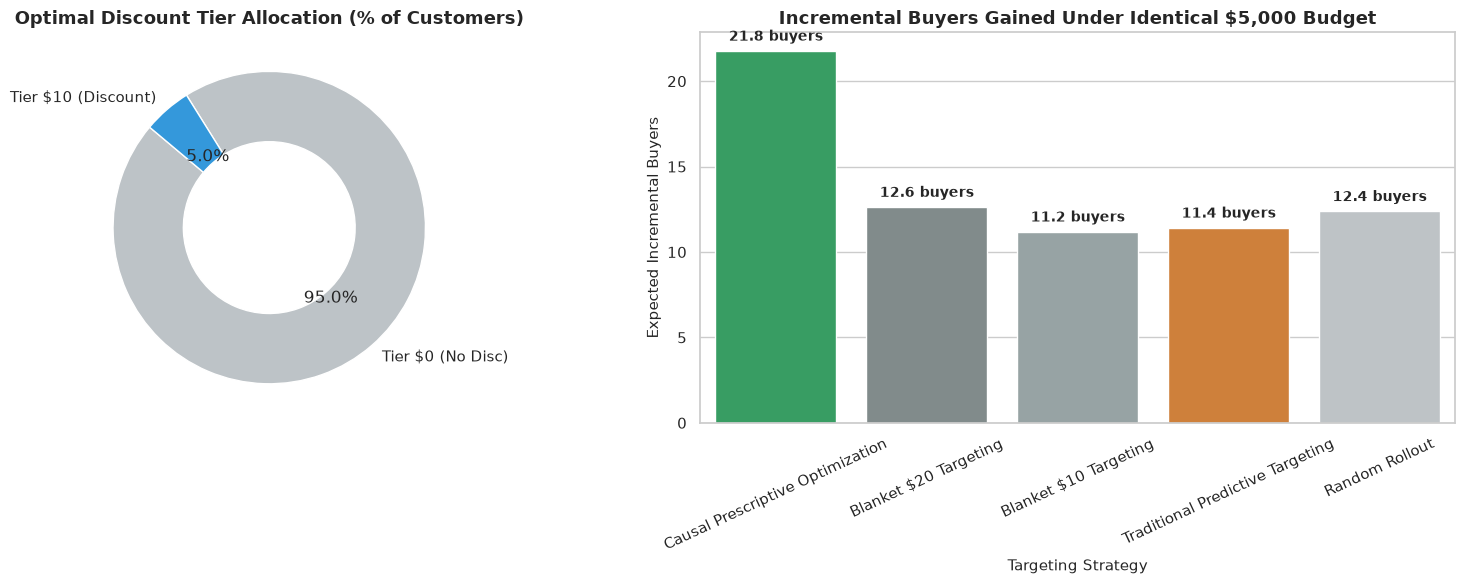

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Donut chart of allocations
counts = greedy_df['recommended_discount'].value_counts().sort_index()
labels = [f"Tier ${t} ({'No Disc' if t==0 else 'Discount'})" for t in counts.index]
colors = ['#bdc3c7', '#3498db', '#2ecc71']

axes[0].pie(
    counts.values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor='w')
)
axes[0].set_title("Optimal Discount Tier Allocation (% of Customers)", fontsize=13, fontweight='bold')

# 2. Bar chart comparing policies
sns.barplot(
    data=comp_df,
    x='Policy Strategy',
    y='Incremental Buyers Gained',
    palette=['#27ae60', '#7f8c8d', '#95a5a6', '#e67e22', '#bdc3c7'],
    ax=axes[1]
)
axes[1].set_title("Incremental Buyers Gained Under Identical $5,000 Budget", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Targeting Strategy", fontsize=11)
axes[1].set_ylabel("Expected Incremental Buyers", fontsize=11)
axes[1].tick_params(axis='x', rotation=25)

for p in axes[1].patches:
    val = p.get_height()
    if val > 0:
        axes[1].annotate(
            f"{val:.1f} buyers",
            (p.get_x() + p.get_width() / 2., val),
            ha='center', va='bottom',
            xytext=(0, 5), textcoords='offset points',
            fontweight='bold', fontsize=10
        )

plt.tight_layout()
plt.show()


### 7. Actionable Prescriptions Matrix Export
Finally, we export the customer-level prescriptive matrix to `data/prescriptive_allocation_matrix.csv` so marketing operations can load the assignments directly into CRM tools (e.g. Klaviyo, Braze, Salesforce).


In [8]:
export_cols = ['client_id', 'age', 'has_redeemed', 'recommended_discount', 'expected_lift', 'treatment_cost']
out_path = 'data/prescriptive_allocation_matrix.csv'
greedy_df[export_cols].to_csv(out_path, index=False)
print(f"Exported {len(greedy_df):,} customer prescriptions to {out_path}.")
print("\nSample Actionable Prescriptions:")
greedy_df[export_cols].head(10)


Exported 10,000 customer prescriptions to data/prescriptive_allocation_matrix.csv.

Sample Actionable Prescriptions:


,client_id,age,has_redeemed,recommended_discount,expected_lift,treatment_cost
0,582caf677d,43,0,0,0.000000,0.0
1,7345cbbfdb,72,1,10,0.043879,10.0
2,ba7e16dc51,43,1,0,0.000000,0.0
3,f47784cc95,38,1,0,0.000000,0.0
4,02a400777e,53,1,0,0.000000,0.0
5,7a517ce4a4,22,0,0,0.000000,0.0
6,c0d16bdfd7,49,1,0,0.000000,0.0
7,0e25715ef8,29,1,0,0.000000,0.0
8,b38ff36548,21,0,0,0.000000,0.0
9,e392204f73,34,1,0,0.000000,0.0
